In [1]:
from google.colab import drive
drive.mount('/content/drive')
# monta o Drive onde ficam os dados processados e os modelos

Mounted at /content/drive


In [2]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, Activation, Concatenate, Conv2DTranspose, BatchNormalization
from tensorflow.keras.applications import EfficientNetB0
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import MeanIoU
import keras
from keras import ops

In [ ]:
# A unica coisa que muda para U-NetEfficientNetB0 é a função de loss

In [ ]:
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.00001

In [ ]:
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

In [ ]:
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [6]:
def decoder_efficientnet(inputs,skips, filters):
    x = Conv2DTranspose(filters, (2,2), strides=2, padding="same")(inputs)
    x = Concatenate()([x,skips])
    x = convolucao(x,filters)
    return x

In [ ]:
def efficientnet_unet(input_shape):
    inputs = Input(input_shape)

    efficientnet = EfficientNetB0(include_top=False, weights="imagenet", input_tensor=inputs)

    #skips
    s1 = inputs
    s2 = efficientnet.get_layer("block2a_expand_activation").output
    s3 = efficientnet.get_layer("block3a_expand_activation").output
    s4 = efficientnet.get_layer("block4a_expand_activation").output
    s5 = efficientnet.get_layer("block6a_expand_activation").output

    # BASE
    b1 = efficientnet.get_layer("top_activation").output

    # DECODER
    d1 = decoder_efficientnet(b1, s5, 512)
    d2 = decoder_efficientnet(d1, s4, 256)
    d3 = decoder_efficientnet(d2, s3, 128)
    d4 = decoder_efficientnet(d3, s2, 64)
    d5 = decoder_efficientnet(d4, s1, 32)

    outputs = Conv2D(5,1, padding='same',activation='softmax')(d5)

    model = Model(inputs,outputs)

    return model

In [8]:
model = efficientnet_unet((height_img, width_img, canais))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 288, 288,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 288, 288,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 288, 288,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 289, 289,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 144, 144,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 144, 144,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 144, 144,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 144, 144,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 144, 144,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 144, 144,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 144, 144,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 144, 144,  │        512 │ block1a_se_excit

 Total params: 17,535,304 (66.89 MB)

 Trainable params: 17,489,313 (66.72 MB)

 Non-trainable params: 45,991 (179.66 KB)

In [ ]:
dice = keras.losses.Dice(axis=(0, 1, 2))
ce = keras.losses.SparseCategoricalCrossentropy()

def ce_dice_loss(y_true, y_pred):
    y_true_oh = ops.one_hot(ops.cast(ops.squeeze(y_true, axis=-1), 'int32'), 5)
    return ce(y_true, y_pred) + dice(y_true_oh, y_pred)
    # mesma loss usada no resnet
    # loss muito utilizada em segmentação em competições do kaggle

In [11]:
model.compile(optimizer=Adam(learning_rate=lr), loss=ce_dice_loss, metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False, name='mean_io_u')])

In [12]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet_dice.keras'

In [13]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.000001, verbose=1)
checks = [checkpointer, lr_reducer, early_stopper]

In [14]:
# treinando o modelo
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - loss: 3.0814 - mean_io_u: 0.0304
Epoch 1: val_mean_io_u improved from None to 0.05816, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet_dice.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet_dice.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 306s 582ms/step - loss: 2.9962 - mean_io_u: 0.0402 - val_loss: 2.8805 - val_mean_io_u: 0.0582 - learning_rate: 1.0000e-05
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - loss: 2.7416 - mean_io_u: 0.0713
Epoch 2: val_mean_io_u improved from 0.05816 to 0.09661, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet_dice.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models

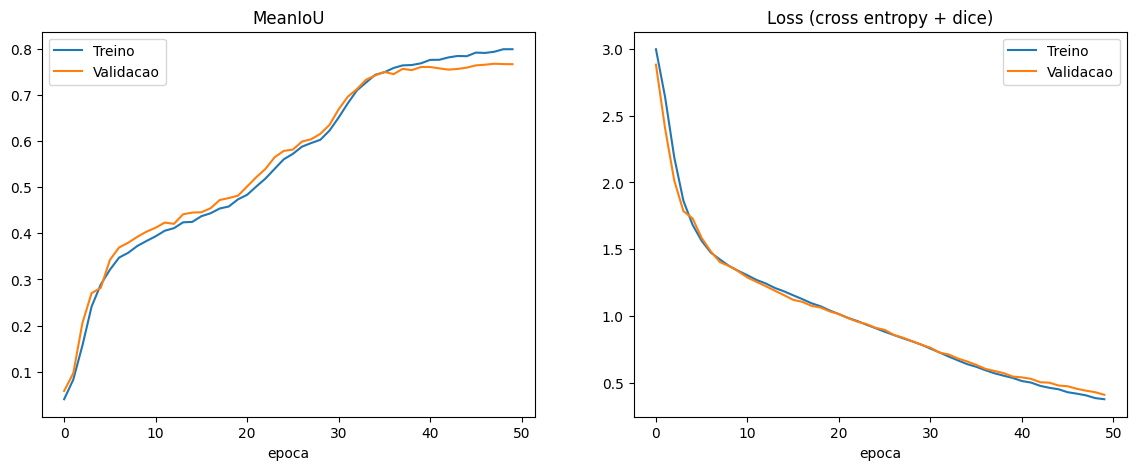

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss (cross entropy + dice)')
plt.xlabel('epoca')
plt.legend()

plt.show()